# Payload thermal — how it works

This is the explanation and reference for `quicksat`'s payload thermal model. It covers the thermal file, the `thermal` column of the payload's consumption file, the heat each surface absorbs and emits, the view factor to the Earth, the account by payload mode, by activity and by orbit, the equilibrium ΔT, and where the model stops.

It is not a tutorial. The worked example is `sample/power/payload_thermal.ipynb`. This notebook still runs, so that it cannot drift from the code. It reads `docs/power/data/`, its own copy of the inputs. The figures quoted below are true of that data.

`docs/explanations/payload_thermal_model.md` explains why the model is built as it is, and `docs/explanations/decisions.md`, entry 26, records the choices. The model is a sub-domain of power, with its code in `quicksat.thermal`. It reads the power folder and the power run, and `python -m quicksat.thermal` prints it after the power budget.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the in-development quicksat package importable without installing it: walk up
# from the current directory to the repo root (the folder that holds the quicksat
# package) and switch to it. Works whether the notebook runs from docs/, the repo
# root, or the docs build.
here = Path.cwd()
repo_root = next(
    (p for p in (here, *here.parents) if (p / "quicksat" / "__init__.py").exists()),
    None,
)
if repo_root is None:
    raise RuntimeError("could not locate the quicksat repo root")
os.chdir(repo_root)

from quicksat import Q_, u
from quicksat.power.config import PowerSystem
from quicksat.power.consumption import PowerConsumption
from quicksat.power.orbits import run_seconds
from quicksat.scenario.config import Scenario
from quicksat.scenario.run import run_scenario
from quicksat.thermal.account import TERMS, equilibrium_dt, run_thermal
from quicksat.thermal.config import Earth, PayloadThermal
from quicksat.thermal.surfaces import (
    STEFAN_BOLTZMANN,
    earth_angular_radius,
    view_factor,
)
from quicksat.utils.plot_helpers import PALETTE, STYLE

plt.style.use(STYLE)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")

DATA = Path("docs") / "power" / "data"
thermal = PayloadThermal.from_yaml_file(DATA / "payload_thermal.yaml")
payload = PowerConsumption.from_csv(DATA / "payload_consumption.csv")
power_system = PowerSystem.from_yaml_file(DATA / "power_system.yaml")
run = run_scenario(Scenario.from_yaml_file(DATA / "scenario.yaml"))
account = run_thermal(thermal, payload, power_system, run)
for note in account.notes:
    print(note)

## The payload's boundary

The payload is wrapped in MLI, which the model takes as a perfect insulator. No heat crosses it. So heat crosses the payload's boundary in four places only:

1. **Dissipation:** the payload's equipment inside the MLI.
2. **Heaters:** the payload's heater lines, together in one row.
3. **Heat flows:** fixed powers in or out, such as through the payload's mounts.
4. **Surfaces:** the radiators, and an aperture if there is one.

Every term is positive when heat goes into the payload. A surface's emission is the one term that is always negative. At each time of the run's grid, the net power into the payload is

$$Q_\text{net} = Q_\text{dissipation} + Q_\text{heaters} + Q_\text{flows} + Q_\text{sun} + Q_\text{albedo} + Q_\text{IR} + Q_\text{emitted}$$

The model gives energies and an equilibrium, not a temperature over time. It has no temperature node and no heat capacity.

## The thermal file

`payload_thermal.yaml` sits in the power folder, beside the power system file. It is optional: without it, the folder sizes power only. It holds three blocks:

| key | meaning | default |
|---|---|---|
| `surfaces` | the surfaces that absorb and radiate heat, each under a name of your choice | required, one at least |
| `heat_flows` | the powers that cross the boundary elsewhere, each under a name of your choice | none |
| `earth` | the Earth's `albedo` and `infrared` flux | 0.30 and 237 W/m² |

Each surface takes these keys:

| key | meaning | default |
|---|---|---|
| `part` | a flat part of the 3D model, which gives the area and the normal | either this, or `normal` and `area` |
| `normal`, `area` | a signed body axis or three numbers, and a positive area | |
| `absorptance` | $\alpha$, the share of sunlight it absorbs, above 0 and at most 1 | required |
| `emissivity` | $\varepsilon$, the share of a black body's infrared it emits, above 0 and at most 1 | required |
| `temperature` | its design temperature, above 0 K | required |
| `fixed_temperature` | true when something else holds it at its temperature | false |

Every block, and the sections `surfaces` and `heat_flows`, may hold its own `comments`, as in the other files. The file of this notebook:

In [2]:
print((DATA / "payload_thermal.yaml").read_text())

# The reference payload thermal file of docs/power/: the payload's surfaces, the
# heat that crosses its boundary elsewhere, and the Earth's two constants.
#
# A copy of the power sample's file. The reference notebook quotes figures from
# it, so change it only together with the notebook.
#
# The payload sits inside MLI, which the model takes as a perfect insulator. So
# heat crosses its boundary in four places only: the dissipation of the rows
# marked inside_mli in payload_consumption.csv, the row marked heater there, the
# heat flows below, and the surfaces below. Every power is positive into the
# payload.

# The surfaces that absorb and radiate heat, each under a name of your choice. A
# surface names a flat part of the 3D model, as a solar panel does, or is typed
# in with a normal in body axes and an area. absorptance is the share of
# sunlight it absorbs, for the year being sized: white paint starts near 0.20 and
# rises to 0.40 or more over a mission. emissivity is the share o

The loader checks each key as it reads the file. A file it refuses gives an error that names the key. A heat flow is read as one power unless it is a mapping, so a mistake in it gives one error, not two:

In [3]:
RADIATOR = (
    "normal: -x, area: 0.3 m2, absorptance: 0.20, emissivity: 0.85, temperature: 273 K"
)


# read a one-off thermal file, and report what the loader makes of it
def read(label, text):
    try:
        PayloadThermal.from_yaml_text(text)
        print(f"{label:34s} accepted")
    except ValueError as error:
        reason = next(
            line.strip() for line in str(error).splitlines()[1:] if line[:2] == "  "
        )
        print(f"{label:34s} refused: {reason.split(' [type=')[0]}")


read("a typed-in radiator", f"surfaces:\n  r: {{{RADIATOR}}}\n")
read("an absorptance of 0", f"surfaces:\n  r: {{{RADIATOR.replace('0.20', '0')}}}\n")
read("0 K", f"surfaces:\n  r: {{{RADIATOR.replace('273 K', '0 K')}}}\n")
read(
    "a part, and a normal",
    f"surfaces:\n  r: {{part: Radiator, {RADIATOR}}}\n",
)
read("no surface", "surfaces: {}\n")
read(
    "a flow by mode with no mode",
    f"surfaces:\n  r: {{{RADIATOR}}}\nheat_flows:\n  rf: {{}}\n",
)
read(
    "a flow in kg",
    f"surfaces:\n  r: {{{RADIATOR}}}\nheat_flows:\n  rf: 3 kg\n",
)
read("an albedo of 1.2", f"surfaces:\n  r: {{{RADIATOR}}}\nearth: {{albedo: 1.2}}\n")

a typed-in radiator                accepted
an absorptance of 0                refused: Value error, absorptance must be above 0 and at most 1 (100 %), got 0.0
0 K                                refused: Value error, Temperature must be above 0 K, got '0.0 K'
a part, and a normal               refused: Value error, a surface gives either part, or normal and area, not both: the part gives its own normal and area
no surface                         refused: Value error, surfaces must define at least one surface
a flow by mode with no mode        refused: Value error, heat flow 'rf' gives no mode: give one power, or a power for each payload mode
a flow in kg                       refused: Value error, Value must have power dimensions, got '3.0 kg'
an albedo of 1.2                   refused: Value error, albedo must be from 0 to 1 (100 %), got 1.2


## Temperatures

Write each temperature in kelvin, such as `293 K`, as the samples do. A temperature in Celsius, such as `20 °C`, `20 Celsius` or `20 deg_C`, is turned into kelvin when the file is read, with astropy's `u.temperature()` equivalency. Kelvin is preferred because astropy reads °C as a unit with an offset, and some ways of writing it do not read. Every computation after the loader works in kelvin, and the output gives every temperature in kelvin. A ΔT is a difference, so it is the same in K as in °C.

In [4]:
for text in ("273 K", "20 °C", "20 Celsius", "20 deg_C"):
    surface = PayloadThermal.from_yaml_text(
        f"surfaces:\n  r: {{{RADIATOR.replace('273 K', text)}}}\n"
    ).surfaces["r"]
    print(f"{text:12s} reads as {surface.temperature:.2f}")
read("20 degC", f"surfaces:\n  r: {{{RADIATOR.replace('273 K', '20 degC')}}}\n")

273 K        reads as 273.00 K
20 °C        reads as 293.15 K
20 Celsius   reads as 293.15 K
20 deg_C     reads as 293.15 K
20 degC                            refused: Value error, 'degC' did not parse as unit: At col 0, degC is not a valid unit. Did you mean deg or deg_C? If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html


## The `thermal` column

Each row of `payload_consumption.csv` says where its heat goes, in its `thermal` column:

| value | meaning |
|---|---|
| `inside_mli` | all the row's power is dissipated inside the payload |
| `outside_mli` | the row's heat goes elsewhere, and the account leaves it out |
| `heater` | the payload's heater lines, all together, which dissipate inside the payload too |

The column is needed only when the folder has the thermal file. Every row then needs a value. A file has one heater row at most, since a mode's balancing heater power is one figure. The platform's file takes no such column, since the model covers the payload only. The heater powers stay in the consumption file, so power and thermal read one number.

**No margins.** Power adds each row's equipment margin and the system margin, since more power is the safe side for power. Less dissipation is the safe side for the heaters, since the payload is then colder. So the account takes each row's power without any margin. For the radiators, this is the optimistic side, as the section on sizing decisions says below. The terms that follow the payload's mode, in W:

In [5]:
print((DATA / "payload_consumption.csv").read_text())
pd.DataFrame(account.mode_watts).T.rename_axis("payload mode")

equipment_id,equipment_name,subsystem,units_on,eqpt_margin,idle,imaging,downlink,comments,thermal
x_band_tx,X-band transmitter,COMM,1,10,0 W,0 W,55 W,About 5-10 W of radio output,inside_mli
mass_memory,SSDR 2 TB,OBDH,1,10,10 W,30 W,25 W,"Standby, recording, playback",inside_mli
payload_electronics,Video processing unit,Payload,1,10,5 W,40 W,5 W,Compresses the images,inside_mli
focal_plane,Focal plane assembly,Payload,1,20,0 W,45 W,0 W,"Detectors, their electronics and coolers; new design",inside_mli
payload_heaters,Payload heater lines,Thermal,1,20,22.1 W,0 W,0 W,"Thermostat mean in idle only, to balance the run; 37.6 W installed",heater



,dissipation,heaters,heat flows
payload mode,,,
idle,15.00,22.10,-3.00
imaging,115.00,0.00,-3.00
downlink,85.00,0.00,-8.00


## Heat flows

A heat flow is a power that crosses the boundary somewhere other than a surface. It is positive into the payload, so `-3 W` means 3 W leave it. A flow is one power for every mode, or a power for each payload mode. A flow by mode needs a power for every payload mode that the run gives, `0 W` included, as the consumption columns do. A mode of a flow that the run does not have is allowed, and noted.

The X-band transmitter's row draws 55 W in `downlink` and is marked `inside_mli`. So all 55 W count as dissipation. The antenna sends about 5 W of it out as radio waves, and the flow `x-band rf` takes those 5 W back out:

In [6]:
pd.DataFrame(
    {mode: thermal.flow_watts(mode) for mode in account.mode_watts}
).rename_axis("heat flow [W]")

,idle,imaging,downlink
heat flow [W],,,
platform interface,-3.00,-3.00,-3.00
x-band rf,0.00,0.00,-5.00


## The surfaces

A surface is defined as a solar panel is, through the same `flat_geometry`. It names a flat part of the 3D model, or is typed in with a normal and an area. A surface under an articulation turns with it. The power system file's self-shadowing switch shades the surfaces as it shades the panels, with the same number of points. The rest of the model does not hide the Earth from a surface.

At each step, a surface of area $A$, emissivity $\varepsilon$ and design temperature $T$ emits

$$Q_\text{emitted} = -\varepsilon \sigma A T^4$$

with $\sigma$ the Stefan-Boltzmann constant. At each step it also absorbs three sources:

$$Q_\text{sun} = \Phi \, \alpha \, A \, \max(\cos\theta, 0) \, L \, \ell$$

$$Q_\text{albedo} = \Phi \, a \, F \, \alpha \, A \, \max(\cos\zeta, 0)$$

$$Q_\text{IR} = q_\text{IR} \, F \, \varepsilon \, A$$

- $\Phi$ is the solar flux, $\alpha$ the surface's absorptance, and $\theta$ the sun's angle to its normal.
- $L$ is the light, the share of the sun's disk that the Earth does not hide. $\ell$ is the share of the surface that the model does not shade.
- $a$ is the Earth's albedo, $F$ the view factor to the Earth, and $\zeta$ the sun's zenith angle at the point below the satellite. The albedo falls to zero over the night side.
- $q_\text{IR}$ is the Earth's infrared flux. It does not depend on the sun, so a surface that faces the Earth absorbs it in eclipse too.

The sun angle is taken outside the umbra only. The radiator of this data faces +y, away from the orbit normal in nadir pointing. This data's 13:30 LTAN puts the sun on the orbit normal's side, at a beta angle of +25°. So the radiator sees no sun in nadir pointing and yaw steering. In sun pointing, the sun lies edge on to it, which the table does not count as time in the sun (`EDGE_ON`). The Svalbard pass rolls the body, and gives it a little. The aperture faces nadir, where the spider and the secondary mirror shade it.

In [7]:
account.surface_table

,surface,part,area [m2],absorptance,emissivity,temperature [K],fixed,lowest sun angle [deg],highest sun angle [deg],in sun [min],peak sun [W],mean sun [W],mean view factor,mean albedo [W],mean Earth infrared [W],emitted [W]
0,radiator,Radiator,0.20,0.20,0.85,273.00,False,75.61,140.32,3.50,5.47,0.04,0.22,0.72,8.93,-53.54
1,aperture,Aperture,0.09,0.90,0.90,273.00,True,25.41,180.00,26.50,83.39,3.83,0.68,6.60,12.97,-25.44


## The view factor

The Earth's two terms depend on how much of the Earth a surface sees: the view factor $F$ of a flat plate to a sphere. It has a closed form in two angles. $\lambda$ is the angle between the surface's normal and nadir. $\rho$ is the Earth's angular radius from the satellite, with $\sin\rho = R_\text{E} / r$. There are three cases:

- **Full view,** $\lambda \le 90^\circ - \rho$: the whole disk lies in front of the plate, and $F = \cos\lambda \, \sin^2\rho$.
- **Partial view,** $90^\circ - \rho < \lambda < 90^\circ + \rho$: the plate's plane cuts the disk, and
$$F = \frac{1}{2} - \frac{1}{\pi} \arcsin\left(\frac{\cos\rho}{\sin\lambda}\right) + \frac{1}{\pi} \left( \sin^2\rho \, \cos\lambda \, \arccos(-\cot\rho \, \cot\lambda) - \cos\rho \sqrt{\sin^2\rho - \cos^2\lambda} \right)$$
- **No view,** $\lambda \ge 90^\circ + \rho$: the Earth lies wholly behind the plate, and $F = 0$.

These are the cases of a differential planar element tilted to a sphere, in J. R. Howell's catalog of radiation configuration factors. They are written here in $\rho$ rather than in the distance over the radius. `nadir_body` gives the direction to nadir in body axes at each step, so $\lambda$ follows the attitude through its slews.

In [8]:
radius = earth_angular_radius(run)
print(f"the Earth's angular radius: {radius.min():.2f} to {radius.max():.2f}")
print(f"sin2 of it, the full view factor: {np.sin(radius.max()) ** 2:.3f} at most")

the Earth's angular radius: 67.69 deg to 68.00 deg
sin2 of it, the full view factor: 0.860 at most


**A check of the closed form.** The partial case is long, and easy to get wrong in the transcription. So it is checked here against the view factor's definition, a sum over the Earth's disk:

$$F = \frac{1}{\pi} \int_\text{disk} \max(\cos\theta, 0) \, d\Omega$$

$\theta$ is the angle between the plate's normal and each direction to the disk. The sum needs no algebra, so it checks each case on its own. The tests check the same. It uses this run's mean angular radius. The tilts include 22° and 158°, near both joins between the cases, at $90^\circ \mp \rho$:

In [9]:
def integrated(cosine, rho, count=2000):
    """The view factor as cos theta / pi summed over the Earth's disk."""
    rho = rho.to_value(u.rad)
    alpha = (np.arange(count) + 0.5) * rho / count
    weights = np.sin(alpha) * rho / count
    phi = np.linspace(0, 2 * np.pi, 2 * count, endpoint=False)
    sine = np.sqrt(1 - cosine**2)
    plate = (
        sine * np.sin(alpha)[:, None] * np.cos(phi)[None]
        + cosine * np.cos(alpha)[:, None]
    )
    inner = np.clip(plate, 0, None).sum(axis=1) * (2 * np.pi / len(phi))
    return float(weights @ inner) / np.pi


rho = Q_(float(np.mean(radius.to(u.deg).value)), "deg")
tilts = np.array([0, 15, 22, 30, 60, 90, 120, 150, 158, 170])
closed = view_factor(np.cos(np.radians(tilts)), rho)
summed = np.array([integrated(np.cos(np.radians(tilt)), rho) for tilt in tilts])
pd.DataFrame(
    {"closed form": closed, "integral": summed, "difference": closed - summed},
    index=pd.Index(tilts, name="tilt to nadir [deg]"),
).style.format("{:.6f}")

,closed form,integral,difference
tilt to nadir [deg],,,
0,0.857404,0.857404,-0.000000
15,0.828189,0.828189,-0.000000
22,0.794971,0.794972,-0.000000
30,0.744777,0.744778,-0.000000
60,0.509488,0.509488,-0.000000
90,0.265443,0.265443,0.000000
120,0.080786,0.080786,0.000000
150,0.002244,0.002244,0.000000
158,0.000000,0.000000,0.000000


The partial view joins both other cases with no step. Edge on, at $\lambda = 90^\circ$, a plate still sees a share of the Earth: $F = (\rho - \sin\rho \cos\rho) / \pi$.

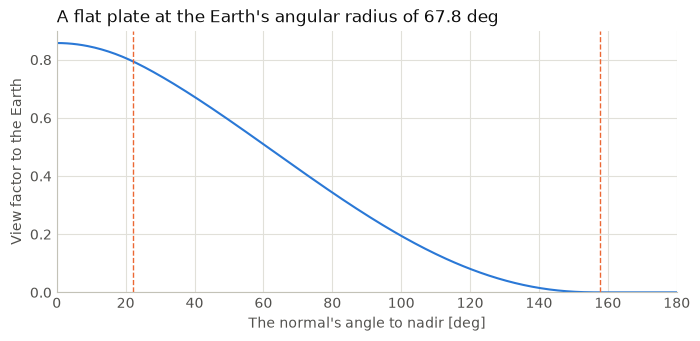

In [10]:
angles = np.linspace(0, 180, 361)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(angles, view_factor(np.cos(np.radians(angles)), rho), color=PALETTE[0])
for edge in (90 - rho.to(u.deg).value, 90 + rho.to(u.deg).value):
    ax.axvline(edge, color=PALETTE[1], linewidth=1, linestyle="--")
ax.set(
    xlim=(0, 180),
    ylim=(0, None),
    xlabel="The normal's angle to nadir [deg]",
    ylabel="View factor to the Earth",
    title=f"A flat plate at the Earth's angular radius of {rho:.1f}",
)
plt.show()

## The energies

The energies follow the power's rules. The terms that follow the payload's mode change at exact times between the grid's steps, so their energy comes from the mode intervals, as the consumption's does. The absorbed powers change linearly between the steps, as the generation does. The emission stays the same through the run. The net energy over the run, worked out exactly and on the grid alone:

In [11]:
seconds = run_seconds(run)
total = account.running_energy[-1]
net = np.asarray(account.net.to(u.W).value)
on_grid = float(np.sum(net[:-1] * np.diff(seconds))) / 3600
terms = sum(np.asarray(account.terms[term].to(u.W).value) for term in TERMS)
print(f"net over the run, exact     {total:.2f}")
print(f"net over the run, on grid   {on_grid:.2f} W h")
print(f"the terms add up to the net: {np.allclose(terms, net)}")

net over the run, exact     -5.97 W h
net over the run, on grid   -5.81 W h
the terms add up to the net: True


## By payload mode

The account sums the net over each payload mode, each activity and each whole orbit. It gives each term as a mean power in W, and the net as a mean power and as an energy in W h. A positive net means heat builds up, and the radiators would run above their design temperature. A negative net means the payload cools, and needs more heater power or a smaller radiator.

The heaters are set per payload mode, so the table by mode is where the heater powers are set. **A mode's balancing heater power** brings the mode's net energy over the run to zero. With $E_\text{mode}$ the mode's net energy before its heaters, and $t_\text{mode}$ the run's time in it,

$$P_\text{balancing} = \max\left(0, -\frac{E_\text{mode}}{t_\text{mode}}\right)$$

It is never below zero, since a heater cannot cool. A mode with a surplus even with no heater shows a radiator that is too small for it.

**The run balancing heater power** brings the run's net energy to zero instead, with the heaters in the modes that lose heat only. Let $D$ be these modes' deficit, $\sum_i P_{\text{balancing},i} \, t_i$, and $G$ the gain of the other modes before their heaters. Each mode that loses heat gets the same share $s$ of its balancing power:

$$P_{\text{run},i} = s \, P_{\text{balancing},i}, \qquad s = \max\left(0, 1 - \frac{G}{D}\right)$$

The share is the part of the deficit that the gain does not cover. So no mode gets more than its balancing power. A share of zero means the run gains heat even with no heater: the radiator is too small.

In [12]:
account.mode_table

,payload mode,time [min],dissipation [W],heaters [W],heat flows [W],sun [W],albedo [W],Earth infrared [W],emitted [W],net [W],net [Wh],ΔT [K],ΔT note,balancing heater [W],run balancing heater [W]
0,idle,231.78,15.00,22.10,-3.00,0.89,7.03,21.83,-78.99,-15.14,-58.47,-21.76,,37.24,23.65
1,imaging,21.00,115.00,0.00,-3.00,0.00,17.49,25.85,-78.99,76.35,26.72,67.71,,0.00,0.00
2,downlink,31.77,85.00,0.00,-8.00,28.25,2.66,19.76,-78.99,48.69,25.78,47.91,,0.00,0.00


The balancing power, from each mode's net and its heaters:

In [13]:
for row in account.mode_table.to_dict("records"):
    before = row["net [W]"] - row["heaters [W]"]
    print(
        f"{row['payload mode']:9s} net {before:7.2f} W before its heaters: "
        f"balancing heater {row['balancing heater [W]']:.2f} W"
    )

idle      net  -37.24 W before its heaters: balancing heater 37.24 W
imaging   net   76.35 W before its heaters: balancing heater 0.00 W
downlink  net   48.69 W before its heaters: balancing heater 0.00 W


The run balancing power, from $D$, $G$ and the share:

In [14]:
table = account.mode_table.set_index("payload mode")
hours = table["time [min]"] / 60
gains = table["net [Wh]"] - table["heaters [W]"] * hours
deficit = (table["balancing heater [W]"] * hours).sum()
gain = gains.clip(lower=0).sum()
share = max(0.0, 1 - gain / deficit)
print(f"D, the cold modes' deficit  {deficit:7.2f} W h")
print(f"G, the other modes' gain    {gain:7.2f} W h")
print(f"s = 1 - G / D               {share:7.3f}")
for mode, row in table.iterrows():
    print(
        f"{mode:9s} s x balancing {share * row['balancing heater [W]']:6.2f} W, "
        f"run balancing heater {row['run balancing heater [W]']:6.2f} W"
    )

D, the cold modes' deficit   143.85 W h
G, the other modes' gain      52.50 W h
s = 1 - G / D                 0.635
idle      s x balancing  23.65 W, run balancing heater  23.65 W
imaging   s x balancing   0.00 W, run balancing heater   0.00 W
downlink  s x balancing   0.00 W, run balancing heater   0.00 W


## By activity

Two activities in one mode can differ. `nadir before eclipse` and `eclipse in nadir` are both in the payload mode `idle`. Only the first is sunlit, so only it sees the sun on the aperture, and the albedo. So the table by activity shows where heat builds up. Each activity counts the slew into it, as the attitude row does, and sums all its occurrences.

In [15]:
account.activity_table

,activity,occurrences,time [min],dissipation [W],heaters [W],heat flows [W],sun [W],albedo [W],Earth infrared [W],emitted [W],net [W],net [Wh],ΔT [K],ΔT note
0,power generation,4,127.03,15.00,22.10,-3.00,0.00,12.02,17.60,-78.99,-15.26,-32.32,-21.97,
1,imaging 45 deg lat,3,19.81,91.57,5.18,-3.00,0.00,20.36,26.35,-78.99,61.46,20.29,57.50,
2,downlink Svalbard,3,31.76,90.51,0.00,-7.08,20.43,4.75,19.46,-78.99,49.08,25.98,48.22,
3,nadir before eclipse,3,13.71,44.84,12.68,-5.13,32.65,0.00,25.86,-78.99,31.92,7.29,33.85,
4,eclipse in nadir,3,92.25,15.00,22.10,-3.00,0.07,0.00,27.11,-78.99,-17.70,-27.22,-26.06,


## By whole orbit

Each whole orbit, counted from the start of the run as `quicksat.power.orbits` counts them for power. A cut orbit at the end is left out.

In [16]:
account.orbit_table

,orbit,start [UTC],dissipation [W],heaters [W],heat flows [W],sun [W],albedo [W],Earth infrared [W],emitted [W],net [W],net [Wh],ΔT [K],ΔT note
0,1,2026-10-01T09:00:00.000,30.72,17.83,-3.60,4.89,7.35,22.32,-78.99,0.53,0.84,0.67,
1,2,2026-10-01T10:34:51.055,30.16,18.01,-3.56,3.93,7.32,21.86,-78.99,-1.25,-1.98,-1.61,
2,3,2026-10-01T12:09:42.109,29.70,18.16,-3.52,2.81,7.27,21.51,-78.99,-3.06,-4.83,-3.98,


## The Earth's values

The defaults, an albedo of 0.30 and an infrared flux of 237 W/m², are means over the whole globe and the year. The local values change with the latitude, the ground below, the clouds and the season. Clouds raise the albedo but lower the infrared, so the two rarely peak together. The shorter the time, the wider the spread. A few minutes over a cloud deck or ice can see much more albedo than the mean, while a whole orbit evens much of it out.

So the right values depend on the scenario: the orbit's inclination, the length of the activities that matter, and the case being sized. NASA TM-2001-211221, *Guidelines for the Selection of Near-Earth Thermal Environment Parameters for Spacecraft Design*, gives hot and cold pairs by inclination and by averaging time. The model takes one pair for the whole run. So a hot case takes higher values throughout, and a cold case lower ones.

The account again, on the same run, with 0.1 more or less albedo, and 25 W/m² more or less infrared:

In [17]:
# the defaults, then the albedo and the infrared each moved down and up
PAIRS = [(0.30, 237), (0.20, 237), (0.40, 237), (0.30, 212), (0.30, 262)]
rows = []
for albedo, infrared in PAIRS:
    earth = Earth(albedo=Q_(albedo, u.one), infrared=Q_(infrared, "W/m2"))
    other = thermal.model_copy(update={"earth": earth})
    modes = run_thermal(other, payload, power_system, run).mode_table
    modes = modes.set_index("payload mode")
    rows.append(
        {
            "albedo": albedo,
            "infrared [W/m2]": infrared,
            **{f"{mode} net [W]": modes.loc[mode, "net [W]"] for mode in modes.index},
            "idle balancing heater [W]": modes.loc["idle", "balancing heater [W]"],
        }
    )
pd.DataFrame(rows)

,albedo,infrared [W/m2],idle net [W],imaging net [W],downlink net [W],idle balancing heater [W]
0,0.30,237,-15.14,76.35,48.69,37.24
1,0.20,237,-17.48,70.52,47.80,39.58
2,0.40,237,-12.79,82.18,49.57,34.89
3,0.30,212,-17.44,73.63,46.60,39.54
4,0.30,262,-12.83,79.08,50.77,34.93


A change of 0.1 in the albedo, or of 25 W/m² in the infrared, moves idle's balancing heater by about 2.3 W, or 6 %. Imaging's net moves by about 6 W with the albedo, since it is sunlit, and by about 3 W with the infrared.

## The equilibrium ΔT

A W h figure alone does not say whether an imbalance matters. So each activity, mode and orbit also gives an equilibrium $\Delta T$. It is how far the surfaces would move from their design temperatures if the activity, the mode or the orbit went on forever. At equilibrium, the heat out equals the heat in, at the mean powers:

$$\sum_i \varepsilon_i \sigma A_i T_i^4 = Q_\text{dissipation} + Q_\text{heaters} + Q_\text{flows} + Q_\text{absorbed}$$

This is one equation, with a temperature for each surface. So the model moves all the floating surfaces by one $\Delta T$, with $T_i = T_{i,\text{design}} + \Delta T$. It solves for it with `scipy.optimize.brentq`. The left side only grows with $\Delta T$, so there is one answer at most. A fixed surface keeps its design temperature, and its emission stays as it is.

There is no $\Delta T$, and the table says why in `ΔT note`, in two cases. When every surface is fixed, nothing can move. When more heat leaves than comes in, even with the floating surfaces at 0 K, no temperature balances the equation.

With one floating surface, $\Delta T$ has a closed form. With $Q_\text{in}$ the heat in, and $Q_\text{fixed}$ the fixed surfaces' emission, which is negative:

$$\Delta T = \left( \frac{Q_\text{in} + Q_\text{fixed}}{\varepsilon \sigma A} \right)^{1/4} - T_\text{design}$$

Idle, worked by hand:

In [18]:
# idle, worked by hand: the radiator floats and the aperture is fixed, so the
# radiator alone balances the heat in less the aperture's emission
idle = account.mode_table.set_index("payload mode").loc["idle"]
inputs = ("dissipation", "heaters", "heat flows", "sun", "albedo", "Earth infrared")
heat_in = sum(idle[f"{name} [W]"] for name in inputs)
radiator = thermal.surfaces["radiator"]
sigma = STEFAN_BOLTZMANN.to_value(u.W / u.m**2 / u.K**4)
area = account.surfaces.surfaces["radiator"].area.to(u.m**2).value
coefficient = radiator.emissivity.to(u.one).value * sigma * area
left = heat_in + account.surfaces.emitted["aperture"]
by_hand = (left / coefficient) ** 0.25 - radiator.temperature.to_value(u.K)
solved, _ = equilibrium_dt(thermal, account.surfaces.emitted, heat_in)
print(f"idle, by hand    {by_hand:.3f} K")
print(f"idle, by brentq  {solved:.3f} K")
print(f"idle, the table  {idle['ΔT [K]']:.3f} K")

idle, by hand    -21.760 K
idle, by brentq  -21.760 K
idle, the table  -21.760 K


## Sizing takes decisions

The account gives the figures. It does not size the payload by itself, since sizing takes decisions that the code cannot take. They come from the mission, from systems engineering and from safety. `docs/explanations/payload_thermal_model.md` lists them, and `sample/power/payload_thermal.ipynb` explains the sample's own.

**The two balancing powers answer different questions.**

- **Each mode's balancing power is the heater to install.** With it, no mode loses heat, but a hot mode still gains heat, since a heater cannot cool. So the run warms from orbit to orbit. A thermostat holds the payload at its set point. Once a hot mode's heat has left, it draws about the cold mode's balancing power to hold it there. So that power must be installed.
- **The run balancing power is the heater's mean draw.** The heater runs in the cold modes only, and the run's net energy comes to zero. The hot modes heat the payload up a little, and the cold modes take that heat back. A thermostat draws this power on average: after a hot mode, it stays off until the extra heat has left, and then holds the set point. The power budget reads the heater row for the heater's energy, so the row takes this figure.

The model keeps one heater power for each mode, so the heater row holds one of the two. The temperature then swings over each orbit, by an amount the model cannot give. With one heated mode, as here, the run balancing power is the run's net energy before the heaters, $E$, over the time in that mode, $t$:

$$P = -\frac{E}{t}$$

This data's heater row runs in idle only:

In [19]:
modes = account.mode_table.set_index("payload mode")
hours = modes["time [min]"] / 60
before = (modes["net [Wh]"] - modes["heaters [W]"] * hours).sum()
heated = ["idle"]
time = hours[heated].sum()
print(f"E, the run's net before its heaters  {before:8.2f} W h")
print(f"t, the time in the heated modes      {time:8.3f} h")
print(f"P = -E / t                           {-before / time:8.2f} W")
idle = modes.loc["idle"]
print(f"idle's run balancing heater          {idle['run balancing heater [W]']:8.2f} W")
print(f"idle's balancing heater, to install  {idle['balancing heater [W]']:8.2f} W")
print(f"the heater row in idle               {idle['heaters [W]']:8.2f} W")

E, the run's net before its heaters    -91.35 W h
t, the time in the heated modes         3.863 h
P = -E / t                              23.65 W
idle's run balancing heater             23.65 W
idle's balancing heater, to install     37.24 W
the heater row in idle                  22.10 W


The row keeps the sample's 22.1 W, which balances the sample's run. This data's scenario keeps the payload in idle through the turn into imaging, so idle lasts longer, and its run needs 23.6 W. The heater power depends on the scenario, as every figure of the account does.

**The radiator's size.** A larger radiator brings the hot modes closer to balance, but the cold modes then need more heater. A smaller one does the reverse. This data lets imaging and downlink heat up a little, for a modest heater in idle. Another systems engineering or safety decision could design the payload colder, with a slightly larger radiator. Imaging and downlink would then come closer to balance, and idle would need more heater power. Both are valid designs.

**The heater to install.** The coldest mode's balancing power covers the scenario's modes, which are its nominal operations. A safe mode, the redundant heater lines, the lowest bus voltage and any margin are left to the user.

**The margins.** The account takes the dissipation without margins, which is the safe side for the heaters. For the radiators, it is the optimistic side. So check them against the dissipation with the margins too: the payload should still balance, with the heater lower.

**The cases.** A hot case, with aged coatings, the most dissipation and a high albedo and infrared, sizes the radiators. A cold case, with new coatings, the least dissipation and a low albedo and infrared, sizes the heaters. Each needs a folder of its own.

## Limitations

What the model does not do, yet or at all:

- **No heat capacity.** The model gives energies and an equilibrium, not a temperature over time. A short activity's ΔT is the one it would reach if it went on forever, which overstates it.
- **No temperature tracking.** Each surface stays at its design temperature through the run.
- **No thermostat.** Each heater line keeps a fixed power for each payload mode. The run balancing power stands for a thermostat's mean draw.
- **One account for the whole payload.** Two radiators at different temperatures add their emissions to one account. The model cannot say whether a cold focal plane radiator matches the focal plane's own heat.
- **Every surface counts in every mode.** An aperture behind a door that opens for imaging is not modelled.
- **No shading of the Earth.** The model's other parts do not hide the Earth from a surface. So the model overstates the Earth's heat: the safe side for the hot case, but not for the cold case.
- **One albedo and one infrared for the run.** They do not follow the latitude, the ground below or the length of an activity.
- **One case a folder.** A hot case at the end of life and a cold case at the start of life each need a folder of their own.
- **Figures only.** The account gives no checks, and no warnings on an imbalance.